# Hierarchical RL — l'Option framework de Sutton, Precup & Singh

**Série** : Reinforcement Learning | **Notebook** : 14 | **Durée estimée** : ~50 min

**Navigation** : [RL-01 CartPole](RL-01-Premiers-Pas-Stable-Baselines3-Python.ipynb) | [RL-05 Tabulaire](RL-05-MDP-Programmation-Dynamique-Q-Learning-Python.ipynb) | [Version C#](RL-14-RL-Hierarchique-Options-CSharp.ipynb) | **RL-14** | [RL-13 Curiosite](RL-13-Curiosite-RND-Python.ipynb) | [RL-15 GRPO](RL-15-GRPO-Comparatif-Multi-Graines-Python.ipynb) | [RL-16 Dream-RSI](RL-16-Dream-RSI-Python.ipynb)

L'apprentissage par renforcement que les notebooks 1 à 13 ont couvert agit **au pas de temps**
: à chaque instant, l'agent choisit une action primaire (haut, bas, gauche, droite). Dès que la
tâche devient longue ou que la récompense est parcimonieuse, ce choix fin-grain est **pénalisant**
: il faut des dizaines de milliers d'actions pour apprendre à travers une séquence de décisions
cohérentes, et le crédit de chaque pas se dilue le long du chemin.

L'abstraction temporelle répond à cela : au lieu d'une action `haut`, l'agent choisit une
**option** — un *macro-comportement* « aller à la porte Ouest », « atteindre le but ». Une option
est une politique qui s'exécute **jusqu'à sa condition de fin**, et l'agent n'a à apprendre que la
séquence de ces macro-actions. C'est le **Option framework** de *Sutton, Precup & Singh (1999)*,
la brique qui relie les MDP « plats » au **RL hiérarchique** (et, en passant, aux *skills* des
agents modernes).

**Objectif de ce notebook** : implémenter le framework depuis zéro sur un **gridworld
quatre-pièces**, et **mesurer** — pas affirmer — le gain de l'abstraction temporelle, en ≥4 seeds,
avec un verdict honnête.

> Prérequis : numpy, matplotlib. Bases de Q-learning (notebook 5) et de SGD/politique (notebook 6).
> Durée : ~50 min.


## Pourquoi l'abstraction temporelle change la donne

Le problème RL standard cherche `Q(s, a)` pour l'action primaire `a`. Deux obstacles apparaissent
dès que l'horizon s'allonge :

1. **Crédit long-horizon** : avec une récompense −1 par pas et +20 au but, un agent qui erre
   de longues traversées ne voit pratiquement aucun signal intermédiaire. La valeur de Bellman
   doit « remonter » de proche en proche, ce qui est lent quand le but est loin.
2. **Exploration dans un grand espace** : pour franchir DEUX portes dans le bon ordre, il faut
   une longue séquence cohérente de pas ; en exploration aléatoire, elle est rare.

L'option framework pose un **MDP semi-markovien (SMDP)** : l'agent raisonne sur les **options**
`o ∈ O`, chacune définie par un triplet `(I_o, π_o, β_o)` :

- `I_o` — **ensemble d'initiation** : les états où l'option peut être choisie ;
- `π_o(s, a)` — la **politique intra-option** : comment agir une fois l'option lancée ;
- `β_o(s)` — la **condition de fin** : probabilité de terminer l'option en `s`.

Exécuter une option ne fait pas **un** pas mais **une séquence** jusqu'à `β`. La transition
SMDP porte donc `(s, o) → (s', τ, r)` : `s'` l'état d'arrivée, `τ` la durée, `r` le retour actualisé intra-option `sum(γ^k r_k)`. On apprend `Q(s, o)` par l'équation de Bellman **au pas de l'option** :

```
Q(s, o) ← Q(s, o) + α [ r + γ^τ · max_{o'} Q(s', o') − Q(s, o) ]
```

**L'état `s` dans la mise à jour est l'état où l'option a été CHOISIE**, pas l'état d'arrivée
`s'` : c'est le petit piège que ce notebook met en évidence. Le choix de haut niveau se fait sur
**5 options** (les portes + le but) au lieu de **4 actions primaires** sur un très long horizon.
**C'est ce qu'on va mesurer — honnêtement, quitte à conclure qu'ici le gain est une case limite**
(des macros BFS sont déjà compétentes, même si les valeurs de haut niveau peuvent évoluer), ce qui prépare
l'intra-option learning, le vrai contenu d'apprentissage du framework.


## Le gridworld quatre-pièces

Un couloir en forme de `+` sépare une grille 15×15 en quatre pièces. Les murs sont intérieurs
(`#`), les portes sont les trous dans les murs : la grille est coupée par une **barre verticale**
(colonnes 7) et une **barre horizontale** (ligne 7), chacune percée de **deux portes**. L'agent
part en haut-gauche `(1,1)` et doit atteindre le coin en bas-droite `(13,13)` — **deux portes à
franchir**, donc un long chemin minimal.

```
#               #               #
#      HAUT      #      HAUT     #
#     GAUCHE     #      DROIT    #
#               #               #
# # # # # # # #  #  # # # # # # #
#               #               #
#    BAS        #     BAS       #
#    GAUCHE     #    DROIT  (G) #
#               #               #
```

- Récompense : **−1** par déplacement, **+20** en atteignant le but (épisode terminé).
- Le but est éloigné → les deux obstacles (crédit long-horizon, exploration) sont réellement là.
- L’agent plat ne reçoit que son état ; les politiques BFS des options utilisent la carte.

On compare deux apprenants **sur les mêmes graines** (3000 épisodes plats contre 1500 à options, jusqu’à 400 pas primitifs par épisode) :

| Apprenant | Actions | Horizon du choix | Ce qu'il doit apprendre |
|-----------|---------|------------------|--------------------------|
| **Flat** (`RL-05` Q-learning) | 4 primitives | chaque pas | toute la séquence de pas |
| **Options** | 5 options (portes + but) | chaque option | la séquence de portes |


In [1]:
import numpy as np
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from collections import deque
import time
import statistics

print("numpy", np.__version__)
print("matplotlib", matplotlib.__version__)


numpy 2.4.4
matplotlib 3.10.9


In [2]:
class FourRooms:
    """Gridworld 15x15 quatre-pièces, but éloigné, récompense -1/pas +20 au but."""
    SIZE = 15
    WALL = 7                 # ligne/colonne des murs intérieurs
    DOORS = (3, 11)          # positions des portes (dans la verticale ET l'horizontale)
    ACTIONS = ["U", "D", "L", "R"]
    DELTA_LIST = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # action = index 0..3
    DOORS_V = [(3, 7), (11, 7)]   # portes de la barre verticale (c=7)
    DOORS_H = [(7, 3), (7, 11)]   # portes de la barre horizontale (r=7)
    ALL_DOORS = DOORS_V + DOORS_H

    def __init__(self, goal=(13, 13)):
        self.goal = goal
        self.start = (1, 1)
        self.n = self.SIZE * self.SIZE

    def is_wall(self, r, c):
        if not (0 <= r < self.SIZE and 0 <= c < self.SIZE):
            return True
        if r == self.WALL and c not in self.DOORS:
            return True
        if c == self.WALL and r not in self.DOORS:
            return True
        return False

    def encode(self, rc):
        r, c = rc
        return r * self.SIZE + c

    def decode(self, s):
        return divmod(s, self.SIZE)

    def open_cells(self):
        return [self.encode((r, c)) for r in range(self.SIZE) for c in range(self.SIZE)
                if not self.is_wall(r, c)]

    def step(self, s, a):
        r, c = self.decode(s)
        dr, dc = self.DELTA_LIST[a]
        nr, nc = r + dr, c + dc
        if self.is_wall(nr, nc):
            return s, -1.0, False
        s2 = self.encode((nr, nc))
        if (nr, nc) == self.goal:
            return s2, 20.0, True
        return s2, -1.0, False

    def bfs_policy(self, target):
        """Politique intra-option : depuis chaque état, l'action qui réduit la distance BFS à
        `target` (état ENCODÉ, int). Retourne (policy, dist)."""
        size = self.SIZE
        dist = {target: 0}
        q = deque([target])
        while q:
            cur = q.popleft()
            r, c = self.decode(cur)
            for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                nr, nc = r + dr, c + dc
                nxt = nr * size + nc
                if (0 <= nr < size and 0 <= nc < size and not self.is_wall(nr, nc)
                        and nxt not in dist):
                    dist[nxt] = dist[cur] + 1
                    q.append(nxt)
        policy = {}
        for s in range(self.n):
            r, c = self.decode(s)
            if self.is_wall(r, c) or s == target:
                continue
            best, bestd = None, 1e9
            for i, (dr, dc) in enumerate(((-1, 0), (1, 0), (0, -1), (0, 1))):
                nr, nc = r + dr, c + dc
                nxt = nr * size + nc
                if (0 <= nr < size and 0 <= nc < size and not self.is_wall(nr, nc)
                        and dist.get(nxt, 1e9) < bestd):
                    bestd = dist[nxt]
                    best = i
            if best is not None:
                policy[s] = best
        return policy, dist

    def bfs_distance(self, target):
        """Distances BFS depuis `target` (état encodé, int) vers tous les états ouverts."""
        size = self.SIZE
        dist = {target: 0}
        q = deque([target])
        while q:
            cur = q.popleft()
            r, c = self.decode(cur)
            for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                nr, nc = r + dr, c + dc
                nxt = nr * size + nc
                if (0 <= nr < size and 0 <= nc < size and not self.is_wall(nr, nc)
                        and nxt not in dist):
                    dist[nxt] = dist[cur] + 1
                    q.append(nxt)
        return dist

env = FourRooms()
print("cellules ouvertes :", len(env.open_cells()), "sur", env.n)
print("but :", env.goal, "| portes :", env.ALL_DOORS)
dgoal = env.bfs_distance(env.encode(env.goal))
print("distance BFS start->goal :", dgoal.get(env.encode(env.start)))


cellules ouvertes : 200 sur 225
but : (13, 13) | portes : [(3, 7), (11, 7), (7, 3), (7, 11)]
distance BFS start->goal : 24


**Lecture de la sortie — l'environnement en trois chiffres.** Avant de lancer le moindre
apprentissage, trois valeurs méritent qu'on s'y arrête :

- **200 cellules ouvertes sur 225** : chaque barre intérieure compte 15 cellules moins ses
  2 portes (13 murs), la croisée `(7,7)` étant partagée — 13 + 13 − 1 = 25 murs, donc 200
  états navigables. L'espace d'états reste petit : c'est voulu, pour que la différence
  entre apprenants vienne de la **structure temporelle** du problème, pas de sa taille.
- **`distance BFS start->goal : 24`** : le chemin optimal fait 24 pas, et il existe
  deux familles de passages (via `(7,3)` puis `(11,7)`, ou via `(3,7)` puis `(7,11)`). Avec −1 par pas et +20
  au but, le retour optimal non actualisé vaut −23 + 20 = **−3** : la récompense est
  presque entièrement absorbée par le coût du trajet. Le signal existe, mais il est loin.
- **Départ `(1,1)`, but `(13,13)`** : coins opposés, deux portes à franchir dans le bon
  ordre — les deux obstacles annoncés (crédit long-horizon, exploration) sont bien là.

> **Note** : la distance BFS est calculée par le **simulateur**, qui connaît la carte.
> Les options BFS utilisent cette carte ; l’agent plat ne la reçoit pas. On mesure ce que
> l'essai-erreur coûte quand la solution est connue du monde mais pas de l'apprenant.

In [3]:
def render_grid(env, path=None):
    size = env.SIZE
    grid = []
    for r in range(size):
        row = []
        for c in range(size):
            if env.is_wall(r, c):
                row.append("#")
            elif (r, c) == env.goal:
                row.append("G")
            elif (r, c) == env.start:
                row.append("S")
            else:
                row.append(".")
        grid.append(row)
    for row in grid:
        print("".join(row))

render_grid(env)
print("\nTrouver le chemin le plus court est facile (BFS). Apprendre à le FAIRE par essai-erreur est lent.")


.......#.......
.S.....#.......
.......#.......
...............
.......#.......
.......#.......
.......#.......
###.#######.###
.......#.......
.......#.......
.......#.......
...............
.......#.......
.......#.....G.
.......#.......

Trouver le chemin le plus court est facile (BFS). Apprendre à le FAIRE par essai-erreur est lent.


**Lecture de la grille.** Le rendu confirme la structure annoncée : ligne 7 et colonne 7
forment une croix de `#`, percée de deux ouvertures chacune — les quatre trous visibles
dans la croix sont les portes. `S` et `G` occupent les coins diagonalement opposés
(haut-gauche, bas-droite).

Deux détails compteront pour la suite :

1. **Aucune pièce ne touche sa diagonale** : aller de `S` à `G` impose de traverser une
   pièce intermédiaire et deux portes — et, dans la pièce intermédiaire, de ressortir par
   la **bonne** porte. Une exploration au hasard des portes fait errer d'une pièce à
   l'autre sans jamais accumuler de progrès.
2. **La dernière ligne de la sortie résume l'enjeu** : le plus court chemin est un
   problème de graphe, résolu en millisecondes par BFS. L'*apprendre* par essai-erreur
   demande d'enchaîner ~24 décisions cohérentes avant le premier signal positif — c'est
   cet écart entre planifier et apprendre que le notebook mesure.

In [4]:
# Option « atteindre la porte (7,3) » : on montre SA politique intra-option (flèches).
def render_option_policy(env, target):
    target_e = env.encode(target) if isinstance(target, tuple) else target
    pol, dist = env.bfs_policy(target_e)
    size = env.SIZE
    arrows = {0: "\u2191", 1: "\u2193", 2: "\u2190", 3: "\u2192"}
    target_rc = env.decode(target_e)
    for r in range(size):
        row = []
        for c in range(size):
            if env.is_wall(r, c):
                row.append("#")
            elif (r, c) == target_rc:
                row.append("*")
            else:
                s = env.encode((r, c))
                row.append((arrows[pol[s]] if s in pol else "."))
        print("".join(row))

print("Politique intra-option de la porte (7,3) — '\u2192' entre dans la porte.")
render_option_policy(env, (7, 3))
print("\nCette politique est DONNÉE (BFS) : l'option est un macro-comportement prêt. Plus bas on l'apprendra.")


Politique intra-option de la porte (7,3) — '→' entre dans la porte.
↓↓↓↓↓↓↓#↓↓↓↓↓↓↓
↓↓↓↓↓↓↓#↓↓↓↓↓↓↓
↓↓↓↓↓↓↓#↓↓↓↓↓↓↓
↓↓↓↓↓↓↓←←←←←←←←
↓↓↓↓↓↓↓#↑↑↑↑↑↑↑
↓↓↓↓↓↓↓#↑↑↑↑↑↑↑
→→→↓←←←#↑↑↑↑↑↑↑
###*#######↑###
→→→↑←←←#↓↓↓↓↓↓↓
↑↑↑↑↑↑↑#↓↓↓↓↓↓↓
↑↑↑↑↑↑↑#↓↓↓↓↓↓↓
↑↑↑↑↑↑↑←←←←←←←←
↑↑↑↑↑↑↑#↑↑↑↑↑↑↑
↑↑↑↑↑↑↑#↑↑↑↑↑↑↑
↑↑↑↑↑↑↑#↑↑↑↑↑↑↑

Cette politique est DONNÉE (BFS) : l'option est un macro-comportement prêt. Plus bas on l'apprendra.


**Lecture de la sortie — que dessinent les flèches ?** Chaque flèche est l'action que
prendrait l'option « atteindre la porte (7,3) » depuis cette cellule : la politique
intra-option `π_o` est définie sur **tous** les états ouverts, pas seulement dans la
pièce de la cible.

- Dans la **pièce haut-gauche**, les flèches descendent vers la rangée 6, convergent vers
  la colonne 3, puis `↓` entre dans la porte — le `*` marque la cible, où l'option
  s'arrête (c'est la condition de fin `β_o`).
- Depuis la **pièce haut-droite**, les flèches descendent vers la rangée 3 puis partent à
  gauche : le chemin passe d'abord par la porte `(3,7)`. Depuis la pièce bas-droite, il
  transite par `(11,7)` puis remonte vers la colonne 3. Autrement dit, cette `π_o` «
  sait » déjà qu'il faut franchir une **autre** porte avant d'atteindre la sienne — le
  routage multi-portes est embarqué dans le macro-comportement.

Et c'est là le point à retenir : cette politique est **calculée par BFS**, donc
**parfaite**. L'option est un macro-comportement tout prêt. Ce que l'agent aurait appris
de moins bon — ou comment apprendre `π_o` au lieu de la recevoir — est renvoyé à
l'intra-option learning, plus bas dans le notebook.

In [5]:
def retour_actualise(rewards, gamma):
    """Somme des recompenses actualisees intra-option, au temps du choix."""
    return sum((gamma ** i) * r for i, r in enumerate(rewards))

def cible_smdp(rewards, gamma, next_q, terminal=False, with_tau=True):
    retour = retour_actualise(rewards, gamma)
    return retour + (0.0 if terminal else (gamma ** len(rewards) if with_tau else gamma) * next_q)

def run_option(env, s, option, max_steps=80, remaining=400, gamma=0.99, timeout_penalty=0.0):
    """Retourne (etat, tau, recompenses, raison, terminal) ; aucune transition gratuite."""
    target, pol, _ = option
    rewards = []
    if s == env.encode(env.goal):
        return s, 0, rewards, 'terminal', True
    if s == target:
        return s, 0, rewards, 'cible', False
    limit = min(max_steps, remaining)
    if limit <= 0:
        return s, 0, rewards, 'budget' if remaining <= 0 else 'timeout', False
    while len(rewards) < limit:
        action = pol.get(s)
        if action is None:
            return s, len(rewards), rewards, 'politique_absente', False
        s, reward, done = env.step(s, action)
        rewards.append(reward)
        if done:
            return s, len(rewards), rewards, 'terminal', True
        if s == target:
            return s, len(rewards), rewards, 'cible', False
    reason = 'budget' if remaining <= max_steps else 'timeout'
    if reason == 'timeout' and timeout_penalty:
        rewards[-1] += timeout_penalty
    return s, len(rewards), rewards, reason, False

s0 = env.encode((1, 1)); t = env.ALL_DOORS[2]
pol_t, _ = env.bfs_policy(env.encode(t)); opt = (env.encode(t), pol_t, None)
s_end, tau, rewards, reason, done = run_option(env, s0, opt)
print(f"depart (1,1) -> porte (7,3) : arrivee {env.decode(s_end)}, tau={tau}, brut={sum(rewards):.2f}, actualise={retour_actualise(rewards,.99):.5f}, arret={reason}")
assert tau == 8 and sum(rewards) == -8 and reason == 'cible' and not done
assert abs(cible_smdp([2,4],.5,10)-6.5)<1e-12
assert abs(cible_smdp([2,4],.5,10,with_tau=False)-9)<1e-12
assert cible_smdp([2,4],.5,10,terminal=True)==4
print("oracles cible : SMDP=6.5 ; ancien retour brut=8.5 ; sans tau=9 ; terminal=4")


depart (1,1) -> porte (7,3) : arrivee (7, 3), tau=8, brut=-8.00, actualise=-7.72553, arret=cible
oracles cible : SMDP=6.5 ; ancien retour brut=8.5 ; sans tau=9 ; terminal=4


**Lecture de la démo — une décision, huit pas.** La politique BFS donnée atteint `(7,3)` en 8 pas : le total brut est −8, tandis que le retour actualisé à `γ=0,99` vaut environ −7,72553. La mise à jour SMDP utilise ce dernier, puis `γ^τ` pour le bootstrap. L'arrêt sur cible, terminal, limite d'option ou budget primitif est distingué. L'agent plat suivant effectue 3000 épisodes, contre 1500 pour les options.

In [6]:
def flat_qlearn(env, seed, episodes=3000, alpha=0.2, gamma=0.99, eps_start=0.4, eps_end=0.05):
    rng = np.random.default_rng(seed)
    n, na = env.n, 4
    Q = [[0.0] * na for _ in range(n)]
    first_solved = None
    solved_last100 = 0
    for ep in range(episodes):
        eps = eps_start + (eps_end - eps_start) * (ep / episodes)
        s = env.encode(env.start)
        done = False
        steps = 0
        while not done and steps < 400:
            if rng.random() < eps:
                a = int(rng.integers(na))
            else:
                vals = Q[s]
                a = vals.index(max(vals))
            s2, r, done = env.step(s, a)
            Q[s][a] += alpha * (r + gamma * max(Q[s2]) - Q[s][a])
            s = s2
            steps += 1
        if done and first_solved is None:
            first_solved = ep
        if ep >= episodes - 100 and done:
            solved_last100 += 1
    return first_solved, solved_last100

SEEDS = [0, 1, 7, 42]
flat_res = {}
for seed in SEEDS:
    t0 = time.time()
    first, last = flat_qlearn(env, seed)
    flat_res[seed] = (first, last)
    print(f"seed={seed:2d}  first_solved={first!s:>5}  solved_last100={last:>3}   ({time.time()-t0:.1f}s)")


seed= 0  first_solved=    8  solved_last100=100   (0.2s)


seed= 1  first_solved=   13  solved_last100=100   (0.3s)


seed= 7  first_solved=   15  solved_last100=100   (0.2s)


seed=42  first_solved=   12  solved_last100=100   (0.3s)


### Lecture et limites

Les quatre lignes indiquent le premier épisode résolu, indexé à partir de zéro, et les succès sur les 100 derniers épisodes. Ces chiffres décrivent les graines exécutées : un premier succès ne prouve pas la convergence.

Pour les graines 0, 1, 7 et 42, les premiers succès surviennent aux épisodes 8, 13, 15 et 12. Chacune réussit les 100 derniers épisodes : le premier succès et la compétence finale sous exploration sont donc deux observations distinctes. Le premier reste sensible aux trajectoires exploratoires ; il ne date pas à lui seul la stabilisation de la politique.


In [7]:
flat_firsts = [v[0] for v in flat_res.values() if v[0] is not None]
flat_lasts = [v[1] for v in flat_res.values()]
print("flat Q-learning, 4 seeds")
print("  épisodes-avant-premier-succès :", flat_firsts)
print("  médiane :", statistics.median(flat_firsts) if flat_firsts else "jamais (sur le budget)")
print("  taux de succès final (100 derniers ép.) :", [f"{v/100:.2f}" for v in flat_lasts])


flat Q-learning, 4 seeds
  épisodes-avant-premier-succès : [8, 13, 15, 12]
  médiane : 12.5
  taux de succès final (100 derniers ép.) : ['1.00', '1.00', '1.00', '1.00']


### Lecture et limites

Le Q-learning plat apprend les actions primitives par essai-erreur. Le premier succès et la réussite des 100 derniers épisodes mesurent deux aspects distincts ; les coûts de calcul dépendent aussi des pas réellement exécutés.

La médiane des premiers succès vaut 12,5 épisodes, avec une dispersion de 8 à 15 ; les quatre taux finaux valent 1,00. Le plat doit découvrir une suite d’actions primitives vers un but situé à 24 pas par BFS. Le coût réel dépend du nombre de pas parcourus pendant chaque épisode, pas seulement du nombre d’épisodes.


**Transition — de la référence au cadre à options.** Le plat a appris, mais il a payé
chaque pas de sa découverte. On munit maintenant l'agent d'un niveau haut qui choisit non
plus des pas mais des **options** — les quatre « atteindre la porte k » et « atteindre le
but ». Deux changements structurels en découlent, tous deux mesurables :

- le choix de haut niveau porte sur **5 options** au lieu de 4 actions, mais il n'est plus
  refait à chaque pas — seulement à la fin de chaque option ;
- la table `Q(s, o)` se met à jour à l'échelle de l'option : récompense cumulée `r`,
  durée `τ`, actualisation `γ^τ`.

Et surtout : ces macros sont **construites par BFS** — parfaites, données. Retenez-le,
c'est ce qui déterminera la lecture des résultats qui viennent.

In [8]:
# On définit les OPTIONS du haut niveau : atteindre chaque porte, et atteindre le but.
def build_options(env):
    options = {}
    for i, door in enumerate(env.ALL_DOORS):
        t = env.encode(door)
        pol, _ = env.bfs_policy(t)
        options[f"porte_{i}"] = (t, pol, None)   # (cible encodée, politique intra-option, initiation)
    g = env.encode(env.goal)
    pol_g, _ = env.bfs_policy(g)
    options["but"] = (g, pol_g, None)
    return options

options = build_options(env)
print("options définies :", list(options.keys()))
for k, (t, pol, _) in options.items():
    print(f"  {k:9s} -> cible {env.decode(t)}  (politique intra-option : {len(pol)} états)")


options définies : ['porte_0', 'porte_1', 'porte_2', 'porte_3', 'but']
  porte_0   -> cible (3, 7)  (politique intra-option : 199 états)
  porte_1   -> cible (11, 7)  (politique intra-option : 199 états)
  porte_2   -> cible (7, 3)  (politique intra-option : 199 états)
  porte_3   -> cible (7, 11)  (politique intra-option : 199 états)
  but       -> cible (13, 13)  (politique intra-option : 199 états)


**Lecture de la sortie — le menu du haut niveau.** Cinq options : quatre « porte k » et
« but ». Deux détails dans la colonne de droite :

- chaque politique intra-option couvre **199 états** — les 200 cellules ouvertes moins la
  cible elle-même : sur sa cible, l'option n'a plus rien à décider, elle s'arrête ;
- les cibles sont exactement les quatre portes et le but : le haut niveau choisit **où
  aller**, chaque choix déléguant le **comment y aller** à sa `π_o`.

Noter l'asymétrie de rythme : le plat lit sa table 200 × 4 une fois par **étape** ; le SMDP
lit sa table 200 × 5 une fois par **option** (le `τ` de la démo était 8 pour une porte
voisine, ~24 pour le but — la distance BFS mesurée au départ). C'est cette différence de
rythme de décision — pas la taille des tables — que la comparaison mesure.

In [9]:
def options_disponibles(options, s, initiation_sets=None):
    noms = []
    for nom, (target, _, initiation) in options.items():
        if s == target:
            continue
        if initiation is not None and not (initiation(s) if callable(initiation) else s in initiation):
            continue
        if initiation_sets is not None and (nom not in initiation_sets or s not in initiation_sets[nom]):
            continue
        noms.append(nom)
    return noms

def smdp_qlearn(env, options, seed, episodes=1500, alpha=0.2, gamma=0.99,
                eps_start=0.4, eps_end=0.05, max_steps=80, step_budget=400,
                initiation_sets=None, timeout_penalty=0.0, runner=run_option,
                with_tau=True, return_details=False, initial_q=None):
    rng = np.random.default_rng(seed)
    names = list(options)
    Q = {name: ([0.0] * env.n if initial_q is None else list(initial_q[name])) for name in names}
    first_solved = None
    solved_last100 = 0
    succes, arrets = [], {}
    for ep in range(episodes):
        eps = eps_start + (eps_end - eps_start) * (ep / episodes)
        s = env.encode(env.start); done = False; budget_steps = 0
        while not done and budget_steps < step_budget:
            available = options_disponibles(options, s, initiation_sets)
            if not available:
                arrets['aucune_option'] = arrets.get('aucune_option', 0) + 1
                break
            if rng.random() < eps:
                name = available[int(rng.integers(len(available)))]
            else:
                name = max(available, key=lambda nm: Q[nm][s])
            s_choose = s
            s, tau, rewards, reason, done = runner(env, s, options[name], max_steps=max_steps,
                remaining=step_budget-budget_steps, gamma=gamma, timeout_penalty=timeout_penalty)
            arrets[reason] = arrets.get(reason, 0) + 1
            if tau != len(rewards) or tau > min(max_steps, step_budget-budget_steps):
                raise ValueError('transition option incoherente')
            if tau == 0:
                break
            budget_steps += tau
            suivant = options_disponibles(options, s, initiation_sets)
            best_next = max((Q[nm][s] for nm in suivant), default=0.0)
            target = cible_smdp(rewards, gamma, best_next, terminal=done, with_tau=with_tau)
            Q[name][s_choose] += alpha * (target - Q[name][s_choose])
        succes.append(int(done))
        if done and first_solved is None:
            first_solved = ep
        if ep >= episodes - 100 and done:
            solved_last100 += 1
    if return_details:
        return first_solved, solved_last100, Q, succes, arrets
    return first_solved, solved_last100

opt_res = {}
for seed in SEEDS:
    t0 = time.time()
    first, last = smdp_qlearn(env, options, seed)
    opt_res[seed] = (first, last)
    print(f"seed={seed:2d}  first_solved={first!s:>5}  solved_last100={last:>3}   ({time.time()-t0:.1f}s)")

# Oracles de frontiere sur les fonctions qui alimentent vraiment l'apprenant.
near = FourRooms(); near.start = (13,12); start_test = near.encode(near.start); goal_test = near.encode(near.goal)
other_target = near.encode((7,3)); one = {'autre': (other_target, {start_test: 3}, None)}
initial = {'autre': [0.0] * near.n}; initial['autre'][goal_test] = 100.0
f, _, qt, _, _ = smdp_qlearn(near, one, 0, episodes=1, alpha=1, eps_start=0, eps_end=0, initial_q=initial, return_details=True)
assert f == 0 and qt['autre'][start_test] == 20 and qt['autre'][goal_test] == 100
end, t, rw, why, done = run_option(env, s0, options['but'], remaining=2)
assert t == 2 and why == 'budget' and not done
assert not options_disponibles({'x': (s0, {}, None)}, s0)
empty = {name:set() for name in options}
f0, _, _, _, stops = smdp_qlearn(env, options, 0, episodes=2, initiation_sets=empty, return_details=True)
assert f0 is None and stops['aucune_option'] == 2
restricted = {'autre': one['autre'], 'interdit': (near.encode((3,7)), {start_test: 3}, None)}
qinit = {k:[0.0]*near.n for k in restricted}; qinit['interdit'][start_test] = 100
f1, _, q1, _, _ = smdp_qlearn(near, restricted, 0, episodes=1, alpha=1, eps_start=0, eps_end=0,
    initial_q=qinit, initiation_sets={'autre': {start_test}, 'interdit': set()}, return_details=True)
assert f1 == 0 and q1['interdit'][start_test] == 100 and q1['autre'][start_test] == 20
_, t, rr, why, done = run_option(env, s0, options['but'], max_steps=2, remaining=10, timeout_penalty=-2)
assert t == 2 and rr == [-1, -3] and why == 'timeout' and not done
assert abs(retour_actualise(rr,.5)-(-2.5))<1e-12
print('oracles learner : terminal/Qbut, etat choisi, budget, timeout, tau0 et initiations vide/restreinte OK')


seed= 0  first_solved=    0  solved_last100=100   (0.0s)
seed= 1  first_solved=    0  solved_last100=100   (0.0s)


seed= 7  first_solved=    0  solved_last100=100   (0.0s)
seed=42  first_solved=    0  solved_last100=100   (0.1s)
oracles learner : terminal/Qbut, etat choisi, budget, timeout, tau0 et initiations vide/restreinte OK


### Lecture et limites

Les politiques de navigation des options sont fournies par BFS. Un éventuel succès à l’épisode 0 montre cette compétence disponible dès le départ ; le niveau haut continue néanmoins à mettre à jour ses valeurs. Quatre graines ne suffisent pas à prouver l’indépendance au hasard.

Les quatre graines rendent ici `first_solved=0` et `solved_last100=100`. Le menu inclut une option « but » dont la politique BFS est déjà compétente : ce premier succès utilise une connaissance fournie, alors que le plat doit découvrir ses actions. Le niveau haut continue toutefois à mettre à jour ses valeurs ; ces quatre observations ne prouvent pas une indépendance générale au hasard.


In [10]:
opt_firsts = [v[0] for v in opt_res.values() if v[0] is not None]
opt_lasts = [v[1] for v in opt_res.values()]
print("SMDP Q-learning (options), 4 seeds")
print("  épisodes-avant-premier-succès :", opt_firsts)
print("  médiane :", statistics.median(opt_firsts) if opt_firsts else "jamais")
print("  taux de succès final :", [f"{v/100:.2f}" for v in opt_lasts])

fm = statistics.median(flat_firsts) if flat_firsts else float("inf")
om = statistics.median(opt_firsts) if opt_firsts else float("inf")
print(f"\nMédiane épisodes-avant-succès : flat={fm}  options={om}")
if fm != float("inf") and om != float("inf") and om > 0:
    print(f"Facteur d'accélération médian : {fm/om:.1f}x")


SMDP Q-learning (options), 4 seeds
  épisodes-avant-premier-succès : [0, 0, 0, 0]
  médiane : 0.0
  taux de succès final : ['1.00', '1.00', '1.00', '1.00']

Médiane épisodes-avant-succès : flat=12.5  options=0.0


### Lecture et limites

Comparer les premiers succès aide à décrire ce protocole, mais les macros BFS reçoivent une information de carte que l’agent plat ne reçoit pas. Leurs budgets sont de 1500 et 3000 épisodes respectivement ; cette comparaison seule ne démontre pas une vitesse d’apprentissage intrinsèque.

La médiane des premiers succès passe de 12,5 pour le plat à 0 pour les options, avec un taux final de 1,00 des deux côtés. Les macros BFS reçoivent une carte dont l’agent plat ne dispose pas, et leurs budgets sont de 1500 et 3000 épisodes respectivement. Le contraste décrit le protocole : il ne sépare pas l’effet de l’abstraction temporelle de celui de la connaissance fournie.


### Exercice 2 — ensembles d'initiation `I_o`

Associer à chaque option les états ouverts de la pièce de sa cible, cible exclue. Convention : une porte sur `r=7` appartient au côté inférieur, une porte sur `c=7` au côté droit ; la porte reste praticable. Comparer avec les options libres sans supposer qu'une restriction préserve l'accessibilité du but.

In [11]:
def room_of(env, rc):
    r, c = rc
    return (2 if r >= env.WALL else 0) + (1 if c >= env.WALL else 0)

def initiation_sets_exo(env, options):
    # TODO : dictionnaire nom -> ensemble d'etats ouverts de la piece de la cible, cible exclue.
    return None

initiation_sets = initiation_sets_exo(env, options)
if initiation_sets is None:
    print("Exercice 2 a completer")
else:
    assert set(initiation_sets) == set(options)
    for name, (target, _, _) in options.items():
        attendu = {s for s in env.open_cells() if s != target and room_of(env, env.decode(s)) == room_of(env, env.decode(target))}
        assert isinstance(initiation_sets[name], set) and initiation_sets[name] == attendu
    _, _, _, _, arrets = smdp_qlearn(env, options, 0, episodes=2, initiation_sets=initiation_sets, return_details=True)
    print("Exercice 2 : domaines verifies, deux episodes executes ; arrets", arrets)

Exercice 2 a completer


### Lecture et limites

Le niveau bas apprend maintenant des tables primitives. À chaque pas, une règle oracle qui connaît la carte choisit la cible BFS la plus proche ; seule la table de cette cible active est mise à jour. La récompense vaut +1 à la cible et −1 sinon.

In [12]:
# On APPREND maintenant les politiques intra-option (au lieu de les donner en BFS).
# Chaque option est « atteindre la porte k » ; on apprend Q_prim(s,a) mais on ne met à jour que
# les états où l'option est ACTIVE (intra-option learning) — c'est le cœur de Sutton et al.
def intra_option_learning(env, targets, seed, episodes=1500, alpha=0.2, gamma=0.99,
                          eps_start=0.5, eps_end=0.08, max_steps=40):
    rng = np.random.default_rng(seed)
    n, na = env.n, 4
    Q = {tid: [[0.0] * na for _ in range(n)] for tid in targets}
    successes = 0
    usage = {t: 0 for t in targets}
    atteintes = {t: 0 for t in targets}
    for ep in range(episodes):
        eps = eps_start + (eps_end - eps_start) * (ep / episodes)
        s = env.encode(env.start)
        done = False
        steps = 0
        while not done and steps < 400:
            # oracle haut-niveau : on choisit l'option dont la cible est la plus proche (BFS),
            # pour ISOLER l'apprentissage bas-niveau (le niveau haut est ici supposé bon).
            tid = min(targets, key=lambda t: bfs_dist[t].get(s, 1e9))
            usage[tid] += 1
            if rng.random() < eps:
                a = int(rng.integers(na))
            else:
                vals = Q[tid][s]
                a = vals.index(max(vals))
            s2, r, done = env.step(s, a)
            target = env.encode(tid)
            r_shaped = 1.0 if s2 == target else -1.0
            Q[tid][s][a] += alpha * (r_shaped + gamma * max(Q[tid][s2]) - Q[tid][s][a])
            s = s2
            steps += 1
            if s2 == target:
                successes += 1
                atteintes[tid] += 1
                break
    return Q, successes, usage, atteintes

# précalcul des distances BFS pour le choix de l'option la plus proche
targets = env.ALL_DOORS
bfs_dist = {t: env.bfs_distance(env.encode(t)) for t in targets}

_Q, succ, usage, atteintes = intra_option_learning(env, targets, SEEDS[0])
print(f"intra-option learning (seed {SEEDS[0]}) : atteintes de sous-objectif = {succ}")
print(f"  -> taux d'atteinte du sous-objectif = {succ/1500:.2f} (sur 1500 épisodes)")
print("actions par cible :", usage, "| atteintes :", atteintes)


intra-option learning (seed 0) : atteintes de sous-objectif = 1459
  -> taux d'atteinte du sous-objectif = 0.97 (sur 1500 épisodes)
actions par cible : {(3, 7): 72743, (11, 7): 0, (7, 3): 66076, (7, 11): 0} | atteintes : {(3, 7): 450, (11, 7): 0, (7, 3): 1009, (7, 11): 0}


### Lecture et limites

Le taux affiché compte les épisodes atteignant une première cible. Les appels et réussites par cible, affichés ci-dessus, révèlent l’exposition inégale ; l’agrégat ne certifie pas l’apprentissage de toutes les politiques. Une seule graine et un oracle de carte limitent la conclusion.

Sur 1500 épisodes, 1459 atteignent une première cible, soit environ 0,97. Le détail révèle 450 atteintes de `(3,7)` et 1009 de `(7,3)` ; `(11,7)` et `(7,11)` ne reçoivent aucune action ni atteinte. L’agrégat ne certifie donc pas l’apprentissage de toutes les portes. Une seule graine et la sélection de cible par un oracle connaissant la carte limitent la portée de ce taux.


### Lecture et limites

Cette expérience isole la mise à jour de la table active. Elle ne réalise pas l’algorithme général hors politique mettant à jour toutes les options compatibles, ni un apprentissage conjoint complet des deux niveaux.

### Exercice 3 — pénalité à l'expiration

Ajouter −2 à la **dernière transition** si une option atteint `max_steps=80` sans cible ni terminal et avant épuisement du budget ; la pénalité reçoit donc le poids `γ^(τ−1)`. Cette modification est un shaping expérimental, pas une garantie générale contre les cycles.

In [13]:
def run_option_penalized(env, s, option, max_steps=80, remaining=400, gamma=.99, timeout_penalty=-2.0):
    # TODO : retourner le meme contrat que run_option avec penalite de -2 au timeout.
    return None

coin = env.encode((0,0)); boucle = (env.encode(env.goal), {coin:0}, None)
r_timeout = run_option_penalized(env, coin, boucle, max_steps=80, remaining=100)
if r_timeout is None:
    print("Exercice 3 a completer")
else:
    # Cas indépendants : mouvement, cible, terminal avant cible, budget nul et coupure.
    near=FourRooms(); near.start=(13,12); sn=near.encode(near.start)
    faux_but=near.encode((7,3)); terminal=(faux_but,{sn:3},None)
    cas=[(env,coin,boucle,80,100),(env,coin,boucle,80,3),
         (env,s0,options['but'],80,2),(env,s0,options['but'],80,0),
         (env,s0,options['porte_2'],80,400),(near,sn,terminal,80,400)]
    for e,s,o,m,b in cas:
        attendu=run_option(e,s,o,max_steps=m,remaining=b,timeout_penalty=-2)
        obtenu=run_option_penalized(e,s,o,max_steps=m,remaining=b,timeout_penalty=-2)
        assert obtenu is not None and obtenu[0]==attendu[0] and obtenu[1]==attendu[1]
        assert obtenu[3:]==attendu[3:] and len(obtenu[2])==len(attendu[2])
        assert all(np.isfinite(x) for x in obtenu[2]) and np.allclose(obtenu[2],attendu[2])
    assert abs(retour_actualise(r_timeout[2],.99) - sum(-.99**i for i in range(80)) + 2*.99**79)<1e-9
    banc={'autre':terminal}; init={'autre':[0.0]*near.n}
    ref=smdp_qlearn(near,banc,0,episodes=2,alpha=1,eps_start=0,eps_end=0,initial_q=init,timeout_penalty=-2,return_details=True)
    obs=smdp_qlearn(near,banc,0,episodes=2,alpha=1,eps_start=0,eps_end=0,initial_q=init,timeout_penalty=-2,runner=run_option_penalized,return_details=True)
    assert ref[0:2]==obs[0:2] and ref[3:]==obs[3:] and np.allclose(ref[2]['autre'],obs[2]['autre'])
    assert obs[0]==0 and obs[2]['autre'][sn]==20
    print("Exercice 3 : transitions et learner vérifiés sur fixtures, y compris terminal et budget")

Exercice 3 a completer


### Lecture et limites

Le tableau suivant résume les premiers succès et les taux finaux sur quatre graines. Les médianes sont absentes si aucun run ne réussit ; l’index zéro reste un succès, distinct de l’absence.

In [14]:
# Verdict multi-seed honnête : on recompile les résultats des DEUX mécanismes.
print("=== VERDICT MULTI-SEED (seeds", SEEDS, ") ===")
print(f"{'méthode':12s} {'first_solved médian':>20s} {'succès final moyen':>20s} {'min/max first':>18s}")
def row(name, res):
    fs = [v[0] for v in res.values() if v[0] is not None]
    last = [v[1] / 100 for v in res.values()]
    med = statistics.median(fs) if fs else None
    mn = min(fs) if fs else "-"
    mx = max(fs) if fs else "-"
    print(f"{name:12s} {str(med):>20s} {f'{statistics.mean(last):.2f}':>20s} {f'{mn}/{mx}':>18s}")
row("flat", flat_res)
row("options", opt_res)

opt_vals = [v[0] for v in opt_res.values() if v[0] is not None]
flat_vals = [v[0] for v in flat_res.values() if v[0] is not None]
adv = statistics.median(opt_vals) if opt_vals else None
flt = statistics.median(flat_vals) if flat_vals else None
print("premier succes median : flat", flt, "options", adv, "(None = aucun succes)")
print("Les options BFS disposent de la carte ; les budgets 3000 et 1500 episodes different.")


=== VERDICT MULTI-SEED (seeds [0, 1, 7, 42] ) ===
méthode       first_solved médian   succès final moyen      min/max first
flat                         12.5                 1.00               8/15
options                       0.0                 1.00                0/0
premier succes median : flat 12.5 options 0.0 (None = aucun succes)
Les options BFS disposent de la carte ; les budgets 3000 et 1500 episodes different.


### Lecture et limites

Le tableau indique les résultats réellement obtenus. Les options bénéficient de politiques BFS fournies, tandis que le plat apprend des actions primitives ; les nombres d’épisodes diffèrent. Ces mesures ne séparent pas l’effet de l’abstraction de celui de la connaissance de la carte.

Le tableau retrouve une médiane de 12,5 épisodes pour le plat, entre 8 et 15, contre 0 pour les options, sans dispersion sur ces quatre graines. Les taux finaux moyens sont de 1,00 pour les deux méthodes. Cette égalité finale ne signifie pas égalité d’apprentissage : politiques BFS fournies et budgets différents empêchent une comparaison à connaissance et coût identiques.


fin courbe flat valeur lissee (moyenne 3 runs, padding zero) : 0.52
fin courbe options valeur lissee (moyenne 3 runs, padding zero) : 0.52


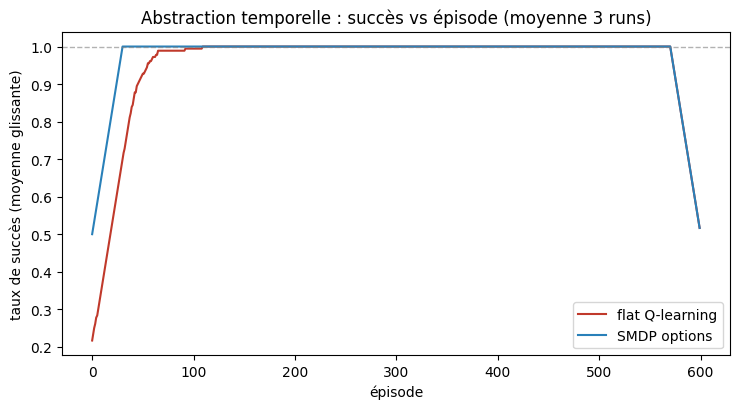

In [15]:
# Courbes moyennes : taux de succès vs épisode (moyenne glissante sur 3 runs).
def run_curve(env, seed, method, episodes):
    rng = np.random.default_rng(seed)
    n = env.n
    succ = []
    if method == "flat":
        Q = [[0.0] * 4 for _ in range(n)]
        for ep in range(episodes):
            s = env.encode(env.start); done = False; steps = 0
            while not done and steps < 400:
                if rng.random() < 0.2:
                    a = int(rng.integers(4))
                else:
                    vals = Q[s]; a = vals.index(max(vals))
                s2, r, done = env.step(s, a)
                Q[s][a] += 0.2 * (r + 0.99 * max(Q[s2]) - Q[s][a])
                s = s2; steps += 1
            succ.append(1 if done else 0)
    else:
        _, _, _, succ, _ = smdp_qlearn(env, options, seed, episodes=episodes,
            eps_start=0.2, eps_end=0.2, return_details=True)
    return succ

EP = 600
win = 60
def smooth(x):
    arr = np.array(x, dtype=float)
    return np.convolve(arr, np.ones(win) / win, mode="same")
curves = {}
for meth in ["flat", "options"]:
    acc = np.zeros(EP)
    for seed in [0, 1, 7]:
        acc += np.array(run_curve(env, seed, meth, EP))
    curves[meth] = smooth(acc / 3)
    print("fin courbe", meth, "valeur lissee (moyenne 3 runs, padding zero) :", round(curves[meth][-1], 2))

plt.figure(figsize=(7.5, 4.2))
plt.plot(curves["flat"], label="flat Q-learning", color="#c0392b")
plt.plot(curves["options"], label="SMDP options", color="#2980b9")
plt.axhline(1.0, ls="--", lw=1, color="gray", alpha=0.6)
plt.ylabel("taux de succès (moyenne glissante)")
plt.xlabel("épisode")
plt.title("Abstraction temporelle : succès vs épisode (moyenne 3 runs)")
plt.legend()
plt.tight_layout()
plt.show()
plt.close()


### Lecture et limites

La courbe représente la moyenne de trois graines, puis une convolution de largeur 60 en mode `same`. Le remplissage par zéros aux bords réduit les derniers points : une réussite brute de 100 % en fin de série donne environ 31/60, pas un taux brut de 0,52. Les deux courbes utilisent 600 épisodes et ε=0,2 fixe.

### Lecture et limites

La comparaison comporte trois volets : Q-learning plat sur quatre graines, SMDP avec politiques BFS fournies sur les mêmes graines et apprentissage bas niveau actif sur une graine. Leurs coûts et connaissances initiales diffèrent ; aucun résultat isolé ne prouve que chaque option est apprise.

Le protocole rassemble trois volets : le plat sur quatre graines, le SMDP avec politiques BFS fournies sur ces mêmes graines et le bas niveau actif sur une seule graine. Les premiers succès médians 12,5/0 décrivent l’accès initial au but ; les 1459/1500 atteintes décrivent une première cible, avec deux portes jamais exposées. Ces résultats répondent à des questions différentes et ne s’additionnent pas en une preuve d’apprentissage conjoint.


### Exercice 4 — durée moyenne `τ`

Pour chaque option, prendre les `n_starts` premiers états ouverts triés où la politique est définie, et mesurer la durée avec `run_option`. Retourner les cinq moyennes. Les deux jeux de départs ci-dessous testent toutes les clés et valeurs finies contre les durées réellement exécutées.

In [16]:
def mean_tau(env, options, n_starts=20):
    # TODO : pour chaque option mesurer run_option sur les premiers etats de sa politique.
    return None

r3, r20 = mean_tau(env, options, 3), mean_tau(env, options, 20)
if r3 is None or r20 is None:
    print("Exercice 4 a completer")
else:
    for n_starts, reponse in ((3,r3),(20,r20)):
        assert set(reponse)==set(options)
        for name, opt in options.items():
            starts=sorted(opt[1])[:n_starts]
            attendu=statistics.mean(run_option(env,s,opt)[1] for s in starts)
            assert np.isfinite(reponse[name]) and abs(reponse[name]-attendu)<1e-9
    print("Exercice 4 : cinq options et deux jeux de departs verifies")

Exercice 4 a completer


## Exercices (à compléter)

Tous les stubs respectent la règle « pas d'erreur volontaire » : complétez, exécutez, commentez.

### Exemple guidé — l'option compte ses pas

Le SMDP tient compte de la **durée** `τ` de l'option (facteur `γ^τ`, comme dans `smdp_qlearn`).
La cellule suivante donne la variante qui remplace `γ^τ` par un simple `γ` : elle ignore donc la
durée de l'option. Elle est résolue et s'exécute telle quelle ; l'exercice 4 ci-dessus mesure
la durée `τ` qui sépare les deux variantes.

Récapitulatif : [initiation](#Exercice-2-—-ensembles-d%27initiation-I_o), [pénalité](#Exercice-3-—-pénalité-à-l%27expiration), [durée moyenne](#Exercice-4-—-durée-moyenne-τ).

In [17]:
# Exemple guidé : seul le facteur de bootstrap change ; retour intra-option identique.
def smdp_qlearn_no_tau(env, options, seed, episodes=600):
    first, _ = smdp_qlearn(env, options, seed, episodes=episodes, eps_start=.2, eps_end=.2, with_tau=False)
    return first

print("smdp_qlearn_no_tau, premier episode resolu (seed 0) :", smdp_qlearn_no_tau(env, options, seed=0))

smdp_qlearn_no_tau, premier episode resolu (seed 0) : 0


## À retenir

Les options BFS fournissent une navigation calculée avec la carte. Le niveau haut apprend des valeurs sur des transitions de durée `τ` ; le retour intra-option est actualisé et le bootstrap utilise `γ^τ`, sauf terminal. Les mesures à 3000 et 1500 épisodes ne sont pas une comparaison à coût identique. L'agrégat bas niveau ne certifie pas toutes les options.

## Vérifiez votre compréhension

<details><summary>Pourquoi actualiser les récompenses à l'intérieur de l'option ?</summary>Chaque récompense survient à un pas primitif différent ; le retour est la somme de `γ^k r_k`.</details>

<details><summary>Que signifie un premier succès à l'épisode zéro ?</summary>La compétence fournie suffit dès le premier épisode ; cela ne prouve ni convergence ni absence de mise à jour des valeurs.</details>

<details><summary>Pourquoi le dernier point lissé peut-il être inférieur au taux brut ?</summary>La convolution `same` utilise des zéros hors de la série, notamment en fin de fenêtre.</details>

## Pour aller plus loin

Sutton, Precup & Singh (1999), *Between MDPs and semi-MDPs* ; Bacon, Harb & Precup (2017), *Option-Critic* ; Vezhnevets et al. (2017), *FeUdal Networks*. Les exercices 2, 3 et 4 portent sur l'initiation, un shaping et la durée.
- [RL-15 — GRPO comparatif multi-graines](RL-15-GRPO-Comparatif-Multi-Graines-Python.ipynb) : prolonger la comparaison multi-graines des algorithmes.

- [PT-12 — crédit multi-étapes différé](../GenAI/PostTraining/PT_12_multistep_delayed_credit.ipynb) : étudier l’attribution du crédit sur une séquence dans le post-entraînement.
